In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import time

In [2]:
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cpu


In [3]:
transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

val_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=128,
    shuffle=False
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 41.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.14MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.55MB/s]


In [ ]:
# For code through pd replace above cell with


# import pandas as pd
# import torch
# from torch.utils.data import TensorDataset, DataLoader

# # Load dataset
# df = pd.read_csv("mnist.csv")

# # Separate features and labels
# X = df.drop("label", axis=1).values
# y = df["label"].values

# # Convert into tensors
# X = torch.tensor(X, dtype=torch.float32) / 255.0
# y = torch.tensor(y, dtype=torch.long)

# # Reshape images into 28x28
# X = X.reshape(-1, 1, 28, 28)

# # Create dataset
# dataset = TensorDataset(X, y)

# # Split dataset
# train_size = int(0.8 * len(dataset))
# val_size = len(dataset) - train_size

# train_dataset, val_dataset = torch.utils.data.random_split(
#     dataset, [train_size, val_size]
# )

# # Create DataLoaders
# train_loader = DataLoader(
#     train_dataset, batch_size=128, shuffle=True
# )

# val_loader = DataLoader(
#     val_dataset, batch_size=128, shuffle=False
# )

In [4]:
class MLP(nn.Module):

    def __init__(self, activation):
        super().__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(28 * 28, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 10)

        self.activation = activation

    def forward(self, x):

        x = self.flatten(x)

        x = self.activation(self.fc1(x))
        x = self.activation(self.fc2(x))
        x = self.fc3(x)

        return x

In [7]:

def train_model(activation, epochs=10):

    model = MLP(activation).to(device)

    optimizer = optim.Adam(model.parameters(), lr=0.001)

    criterion = nn.CrossEntropyLoss()

    train_losses = []
    val_accuracies = []

    gradient_norms = {
        "fc1": [],
        "fc2": [],
        "fc3": []
    }

    epoch_times = []

    for epoch in range(epochs):

        start_time = time.time()

        model.train()

        running_loss = 0.0

        layer_gradients = {
            "fc1": 0.0,
            "fc2": 0.0,
            "fc3": 0.0
        }

        num_batches = 0

        # Training
        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            # Calculate gradients of each layer
            for name, layer in [
                ("fc1", model.fc1),
                ("fc2", model.fc2),
                ("fc3", model.fc3)
            ]:

                total_grad = 0.0

                for param in layer.parameters():

                    if param.grad is not None:
                        total_grad += param.grad.norm(2).item()

                layer_gradients[name] += total_grad

            optimizer.step()

            running_loss += loss.item()

            num_batches += 1

        # Average training loss
        epoch_loss = running_loss / len(train_loader)

        train_losses.append(epoch_loss)

        # Average gradient for each layer
        for name in layer_gradients:

            avg_grad = layer_gradients[name] / num_batches

            gradient_norms[name].append(avg_grad)

        # Calculate training time
        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.time() - start_time

        epoch_times.append(epoch_time)

        # Validation
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)

                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        val_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {epoch_loss:.4f} "
            f"Val Accuracy: {accuracy:.2f}% "
            f"Time: {epoch_time:.2f}s"
        )

    total_time = sum(epoch_times)

    print("Total Training Time:", round(total_time, 2), "seconds")

    return train_losses, val_accuracies, gradient_norms, epoch_times


In [8]:
results = {}

activations = {
    "Sigmoid": nn.Sigmoid(),
    "Tanh": nn.Tanh(),
    "ReLU": nn.ReLU()
}

for name, activation in activations.items():

    print("\n" + "=" * 60)
    print(f"Training MLP with {name}")
    print("=" * 60)

    loss, accuracy, gradients, times = train_model(
        activation,
        epochs=10
    )

    results[name] = {
        "loss": loss,
        "accuracy": accuracy,
        "gradient": gradients,
        "time": times
    }


Training MLP with Sigmoid
Epoch [1/10] Loss: 0.7120 Val Accuracy: 92.23% Time: 11.00s
Epoch [2/10] Loss: 0.2308 Val Accuracy: 94.11% Time: 10.87s
Epoch [3/10] Loss: 0.1663 Val Accuracy: 95.69% Time: 10.87s
Epoch [4/10] Loss: 0.1289 Val Accuracy: 96.32% Time: 10.82s
Epoch [5/10] Loss: 0.1030 Val Accuracy: 96.83% Time: 10.40s
Epoch [6/10] Loss: 0.0833 Val Accuracy: 96.93% Time: 9.97s
Epoch [7/10] Loss: 0.0685 Val Accuracy: 97.32% Time: 10.43s
Epoch [8/10] Loss: 0.0571 Val Accuracy: 97.38% Time: 10.93s
Epoch [9/10] Loss: 0.0471 Val Accuracy: 97.72% Time: 11.02s
Epoch [10/10] Loss: 0.0396 Val Accuracy: 97.83% Time: 11.16s
Total Training Time: 107.49 seconds

Training MLP with Tanh
Epoch [1/10] Loss: 0.3419 Val Accuracy: 94.57% Time: 10.97s
Epoch [2/10] Loss: 0.1522 Val Accuracy: 96.03% Time: 11.04s
Epoch [3/10] Loss: 0.1044 Val Accuracy: 96.58% Time: 11.41s
Epoch [4/10] Loss: 0.0771 Val Accuracy: 97.34% Time: 11.14s
Epoch [5/10] Loss: 0.0567 Val Accuracy: 97.29% Time: 11.07s
Epoch [6/10] 

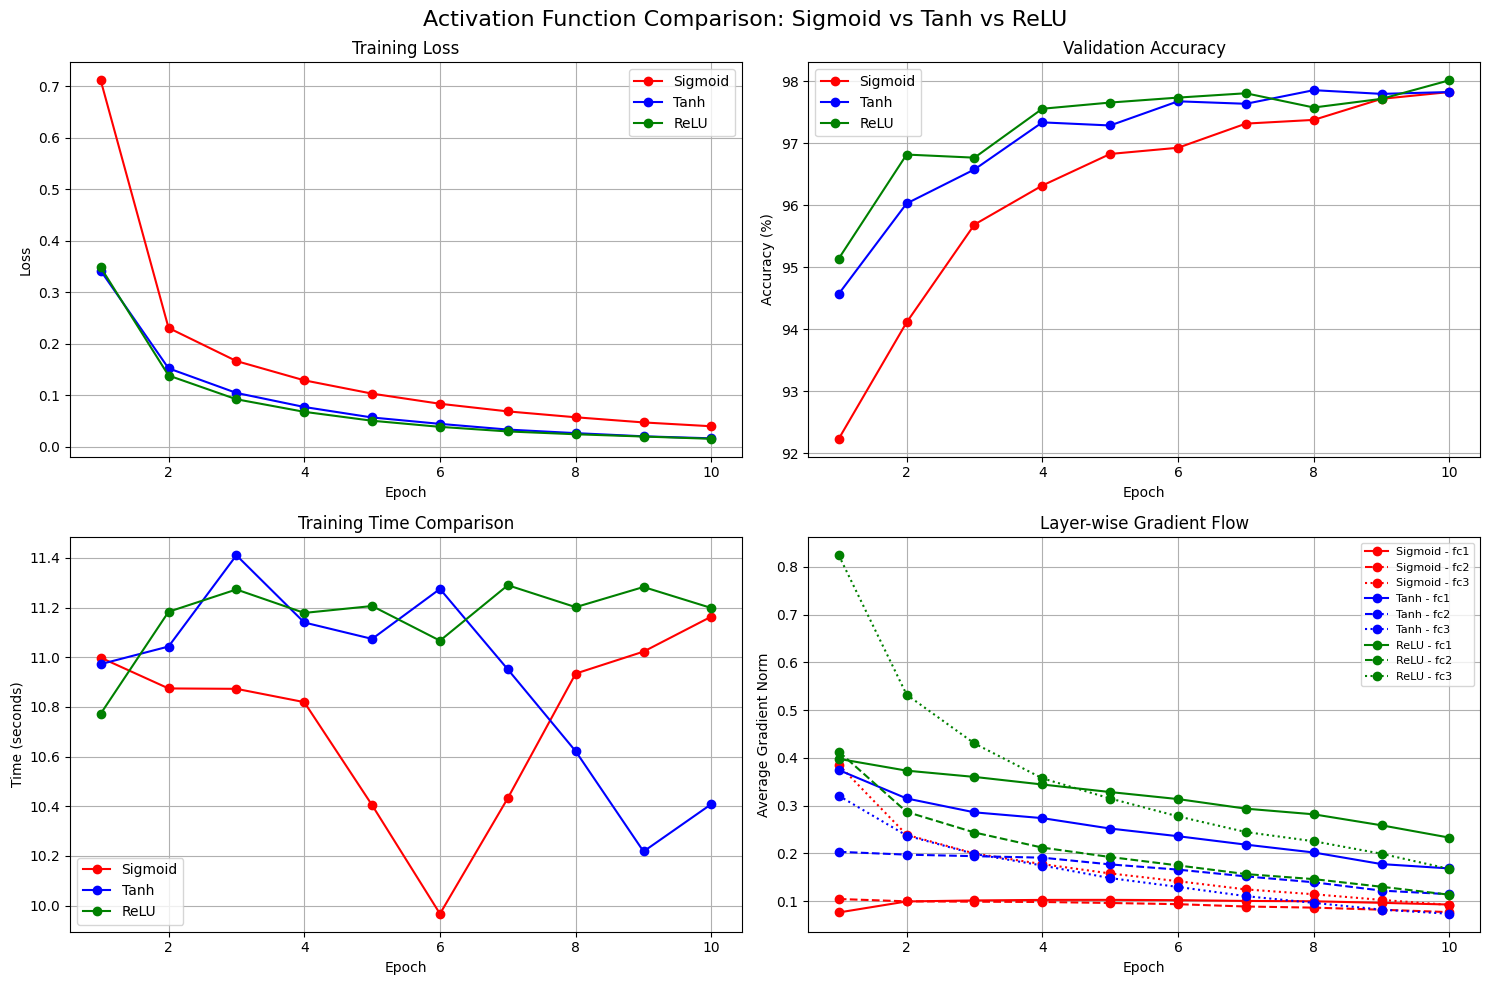

In [9]:
epochs = range(1, 11)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

colors = {
    "Sigmoid": "red",
    "Tanh": "blue",
    "ReLU": "green"
}

# 1. Training Loss

for name in activations:

    axes[0, 0].plot(
        epochs,
        results[name]["loss"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[0, 0].set_title("Training Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)


# 2. Validation Accuracy

for name in activations:

    axes[0, 1].plot(
        epochs,
        results[name]["accuracy"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[0, 1].set_title("Validation Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy (%)")
axes[0, 1].legend()
axes[0, 1].grid(True)


# 3. Training Time

for name in activations:

    axes[1, 0].plot(
        epochs,
        results[name]["time"],
        color=colors[name],
        marker="o",
        label=name
    )

axes[1, 0].set_title("Training Time Comparison")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Time (seconds)")
axes[1, 0].legend()
axes[1, 0].grid(True)


# 4. Layer-wise Gradient Flow

linestyles = {
    "fc1": "-",
    "fc2": "--",
    "fc3": ":"
}

for name in activations:

    for layer in ["fc1", "fc2", "fc3"]:

        axes[1, 1].plot(
            epochs,
            results[name]["gradient"][layer],
            color=colors[name],
            linestyle=linestyles[layer],
            marker="o",
            label=f"{name} - {layer}"
        )

axes[1, 1].set_title("Layer-wise Gradient Flow")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Average Gradient Norm")
axes[1, 1].legend(fontsize=8)
axes[1, 1].grid(True)


plt.suptitle(
    "Activation Function Comparison: Sigmoid vs Tanh vs ReLU",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [10]:
print("\nFINAL MODEL COMPARISON")

print("-" * 65)

print(
    f"{'Activation':<15}"
    f"{'Accuracy':<15}"
    f"{'Total Time':<15}"
)

print("-" * 65)

for name in activations:

    accuracy = results[name]["accuracy"][-1]

    total_time = sum(results[name]["time"])

    print(
        f"{name:<15}"
        f"{accuracy:<15.2f}"
        f"{total_time:<15.2f}"
    )

print("-" * 65)


FINAL MODEL COMPARISON
-----------------------------------------------------------------
Activation     Accuracy       Total Time     
-----------------------------------------------------------------
Sigmoid        97.83          107.49         
Tanh           97.83          109.12         
ReLU           98.02          111.65         
-----------------------------------------------------------------
